This is the project for Statistical Inference in High Energy Physics. I am going to utlize all of the things that I have learned in the course on a supernova dataset.

The following data was used to discover the acceleration of the universe. Here's the link corresponding to it: https://www.sr.bham.ac.uk/~smcgee/ObsCosmo/data.dat. The text file does contain any headers for the data so we list the headers here: Redshift, Redshift uncertainty, Observed peak magnitude, Uncertainty in peak magnitude, Galactic extinction correction, K-correction, Peak magnitude after extinction and K-corrections, Light-curve-corrected magnitude, Total uncertainty in corrected magnitude. Below there's a brief description what these headers physically mean:

* **`z`**: Redshift of the supernova, indicating its recession velocity and cosmological distance.
* **`sigma_z`**: Uncertainty or measurement error associated with the redshift (`z`).
* **`m_peak`**: Observed peak apparent magnitude of the supernova.
* **`sigma_m_peak`**: Uncertainty or measurement error in the peak apparent magnitude (`m_peak`).
* **`extinction`**: Magnitude correction accounting for light absorption by dust.
* **`K_correction`**: Correction factor for shifting between photometric passbands.
* **`m_B_peak`**: Observed peak apparent magnitude in the $B$ (Blue) filter band.
* **`m_B_corrected`**: Peak $B$-band apparent magnitude corrected for dust and K-corrections.
* **`sigma_m_B_corrected`**: Uncertainty in the corrected $B$-band peak magnitude.

First task is to format the data properly and then plot it:


In [27]:
import pandas as pd

columns = [
    "z",
    "sigma_z",
    "m_peak",
    "sigma_m_peak",
    "extinction",
    "K_correction",
    "m_B_peak",
    "m_B_corrected",
    "sigma_m_B_corrected"
]

df = pd.read_csv(
    "supernovaproject.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print(df.head())
print(df.shape)
print(df.describe()) # This will give you a summary of the dataset, including count(empty datasets), mean, std, min, 25%, 50%, 75%, and max(quantiles) for each column.

       z  sigma_z  m_peak  sigma_m_peak  extinction  K_correction  m_B_peak  \
0  0.458    0.001   22.12          0.10        0.03         -0.72     22.81   
1  0.354    0.001   22.08          0.10        0.11         -0.58     22.55   
2  0.425    0.001   21.52          0.21        0.03         -0.68     22.17   
3  0.374    0.001   21.28          0.06        0.10         -0.61     21.79   
4  0.420    0.001   22.37          0.06        0.42         -0.68     22.63   

   m_B_corrected  sigma_m_B_corrected  
0          23.11                 0.46  
1          22.38                 0.33  
2          22.13                 0.49  
3          21.72                 0.22  
4          22.55                 0.25  
(60, 9)
               z    sigma_z     m_peak  sigma_m_peak  extinction  \
count  60.000000  60.000000  60.000000     60.000000   60.000000   
mean    0.361567   0.003200  20.949000      0.060833    0.160167   
std     0.238090   0.004719   2.495987      0.057173    0.141846   
min  

We now plot the magnitudes for different redshifts to get a view what we have on our hands.

In [28]:
import numpy as np
import scipy.stats as stats
from scipy.stats import truncexpon
from scipy.stats import truncnorm
from scipy.stats import chi2
from scipy.stats import norm
import iminuit
from iminuit import Minuit
import matplotlib.pyplot as plt
from matplotlib import container
plt.rcParams["font.size"] = 10
print("iminuit version:", iminuit.__version__)

iminuit version: 2.32.0


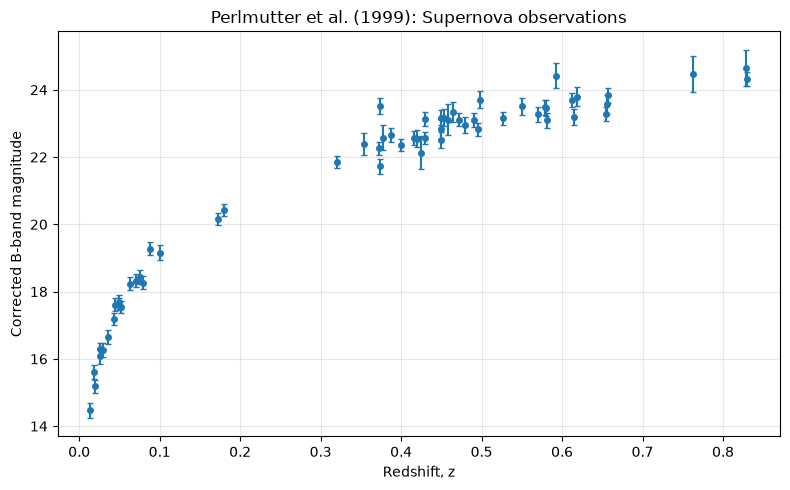

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.errorbar(
    df["z"],
    df["m_B_corrected"],
    yerr=df["sigma_m_B_corrected"],
    fmt="o",
    markersize=4,
    capsize=2
)




plt.xlabel("Redshift, z")
plt.ylabel("Corrected B-band magnitude")
plt.title("Perlmutter et al. (1999): Supernova observations")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

We have plotted the corrected magnitudes v/s redshift. This plot has some distinct features like at lower redshift there seems lesser error on the magnitudes, it also kind of looks like a logarithmic function. To understand why we have to look into some mathematical expressions.

The apparent magnitude has a relation with the Luminosity distance given by:

$$m - M = 5 \log_{10}\left(\frac{d_{L}}{10\text{ pc}}\right)$$

* **$m$**: Apparent magnitude (brightness as observed from Earth)
* **$M$**: Absolute magnitude (apparent magnitude if placed at $10\text{ pc}$)
* **$d_{L}$**: Luminosity distance in parsecs ($1\text{ pc} \approx 3.26156\text{ light-years}$)


 For a flat $\Lambda\text{CDM}$ universe, we can write the luminosity distance as

$$d_L(z) = \frac{c}{H_0} (1+z) \int_0^z \frac{dz'}{E(z')},$$

where

$$E(z') = \sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}.$$

Substituting this expression into the distance modulus gives

$$m = M_B + 5 \log_{10} \left[ \frac{c}{H_0} (1+z) \int_0^z \frac{dz'}{E(z')} \right] + 25.$$

We can separate the terms involving $H_0$ from those involving redshift and $\Omega_m$:

$$m = 5 \log_{10} \left[ (1+z) \int_0^z \frac{dz'}{E(z')} \right] + \underbrace{\left[ M_B + 25 + 5 \log_{10} \left( \frac{c/H_0}{\text{Mpc}} \right) \right]}_{\text{intercept}}.$$

Therefore, our model is

$$\boxed{m_{\text{model}}(z) = 5 \log_{10} D_L(z; \Omega_m) + \mathcal{M}}$$

where $D_L$ is the dimensionless luminosity distance and

$$\boxed{\mathcal{M} = M_B + 25 + 5 \log_{10} \left( \frac{c/H_0}{\text{Mpc}} \right)}$$

So what we do now is code up our apparent magnitude in $\Lambda CDM$ cosmology: 

In [30]:
import numpy as np
from scipy.integrate import quad
from scipy.optimize import minimize

In [31]:
def Luminositydistance(Omega_m, z_prime):
    def E(z_prime):
        return 1/(np.sqrt((Omega_m * (1 + z_prime) ** 3 + (1 - Omega_m))))
    integral,_ = quad(E, 0, z_prime)
    return (1 + z_prime) * integral


Now we add up this correction to our "calculated magnitudes".

In [32]:
def predicted_magnitude(z, Omega_m, intercept):
    dL = Luminositydistance(Omega_m, z)

    return 5 * np.log10(dL) + intercept

In the model that we have defined above there are two parameters namely $\Omega_m$ and $\mathcal{M}$. We are going to estimate thses two using negative likelihood minimization. We are going to do it in two ways, with and without using Minuit.

In [33]:
def nll(parameters, z, m, sigma_m):
    Omega_m, intercept = parameters
    if Omega_m <= 0 or Omega_m >= 1:
        return np.inf  # Return a large value for invalid Omega_m

    m_model = np.array([predicted_magnitude(z_i, Omega_m, intercept) for z_i in z])
    chi2 = np.sum(((m - m_model) / sigma_m) ** 2)
    return 0.5*chi2

In [34]:
#convering the data to numpy arrays for optimization
z = df["z"].to_numpy()
m_obs = df["m_B_corrected"].to_numpy()
sigma = df["sigma_m_B_corrected"].to_numpy()

#k=np.argmin(nll(0.3, 24, z, m_obs, sigma))
initial_guess = [0.3, 24]
result = minimize(nll, initial_guess,args=(z, m_obs, sigma),method="Nelder-Mead") #https://en.wikipedia.org/wiki/Nelder%E2%80%93Mead_method this link will take you to the minimization scheme used in the code. It is a simplex method for function minimization.

Omega_m_mle, intercept_mle = result.x

print("Optimization successful:", result.success)
print("Best-fit Omega_m:", Omega_m_mle)
print("Best-fit intercept:", intercept_mle) 
print("Goodness of fit:", 2 * result.fun/(len(z)-2)) # 2*result.fun is the minimum chi-square value, and len(z)-2 is the degrees of freedom (number of data points minus number of fitted parameters).

Optimization successful: True
Best-fit Omega_m: 0.31820210979869445
Best-fit intercept: 23.99517222890281
Goodness of fit: 1.7782123374441794


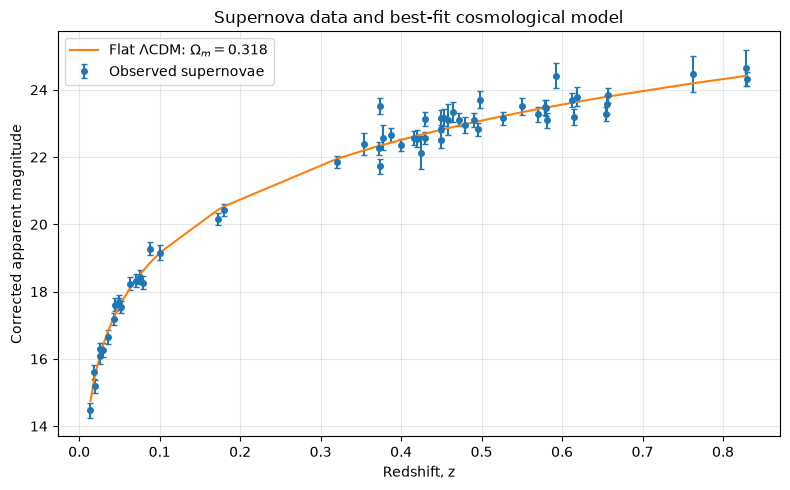

In [35]:
import numpy as np
import matplotlib.pyplot as plt

Omega_m_fit, intercept_fit = result.x

m_fit = np.array([predicted_magnitude(zi, Omega_m_fit, intercept_fit) for zi in z])

# Sort the data by redshift for a clean model curve
order = np.argsort(z)

plt.figure(figsize=(8, 5))

plt.errorbar(
    z, m_obs,
    yerr=sigma,
    fmt="o",
    markersize=4,
    capsize=2,
    label="Observed supernovae"
)

plt.plot(z[order],m_fit[order],label=fr"Flat $\Lambda$CDM: $\Omega_m={Omega_m_fit:.3f}$")

plt.xlabel("Redshift, z")
plt.ylabel("Corrected apparent magnitude")
plt.title("Supernova data and best-fit cosmological model")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The present day value of matter density parameter, $\Omega_m$ is about 0.3049 from WMAP and Planck, or 0.298 ± 0.022 from Type Ia supernovae like Pantheon. So we can see the estimator we got is fairly correct. We have also fitted our model with the data and it is safe to say it works fine. Now we try out Minuit to reproduce these results and also try to plot the profile likelihood and confidence intervals for our estimators.

In [36]:
def neg_log_likelihood(par):
    Omega_m=par[0]
    intercept = par[1]
    if Omega_m <= 0 or Omega_m > 1:
        return np.inf  # Return a large value for invalid Omega_m
    
    m_model = np.array([predicted_magnitude(z_i, Omega_m, intercept) for z_i in z])
    chi2 = np.sum(((m_obs - m_model) / sigma) ** 2)
    return 0.5*chi2
  

In [37]:
parin=np.array([0.4, 24.]) # initial parameter values
parname=["Omega_m", "intercept"]
parnamelatex=[r'$\Omega_m$', r'$intercept$']

parstep = np.array([0.001, .1]) # initial setp sizes
parfix = [False, False] # change these to fix/free parameters
parlim = [(0.,1.), (None, None)] # set limits
m = Minuit(neg_log_likelihood, parin, name=parname)
m.errors = parstep
m.fixed = parfix
m.limits = parlim
m.errordef = 0.5 # errors from lnL = lnLmax - 0.5

In [38]:
m.migrad()                                        
MLE = m.values                                    
sigmaMLE = m.errors                               
cov = m.covariance                                
rho = m.covariance.correlation()                  
    
print(r"par index, name, estimate, standard deviation:")
for i in range(m.npar):
    if not m.fixed[i]:
        print("{:4d}".format(i), "{:<10s}".format(m.parameters[i]), " = ",
         "{:.6f}".format(MLE[i]), " +/- ", "{:.6f}".format(sigmaMLE[i]))

print()
print(r"free par indices, covariance, correlation coeff.:")
for i in range(m.npar):
    if not(m.fixed[i]):
        for j in range(m.npar):
            if not(m.fixed[j]):
                print(i, j, "{:.6f}".format(cov[i,j]), "{:.6f}".format(rho[i,j]))



par index, name, estimate, standard deviation:
   0 Omega_m     =  0.318268  +/-  0.084498
   1 intercept   =  23.995200  +/-  0.048575

free par indices, covariance, correlation coeff.:
0 0 0.007220 1.000000
0 1 0.003353 0.812278
1 0 0.003353 0.812278
1 1 0.002360 1.000000


Profiling each estimator:

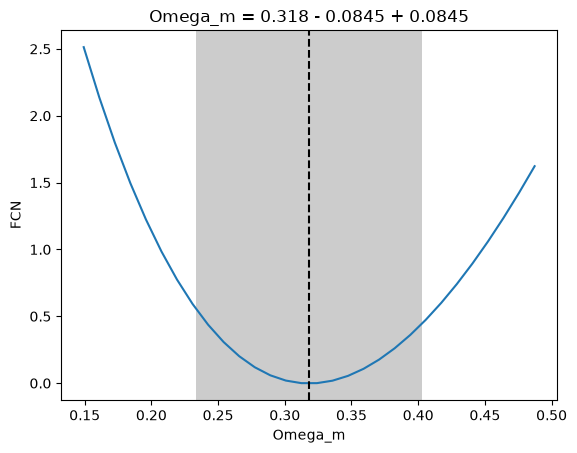

In [39]:
if not(m.fixed['Omega_m']):
    plt.figure()
    m.draw_mnprofile('Omega_m')
    plt.show()

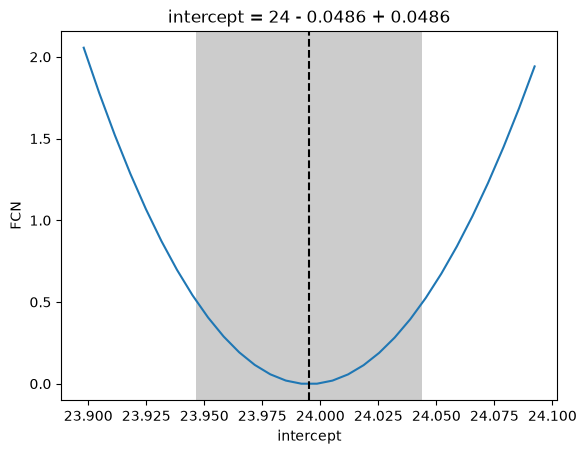

In [40]:
if not(m.fixed['intercept']):
    plt.figure()
    m.draw_mnprofile('intercept')
    plt.show()

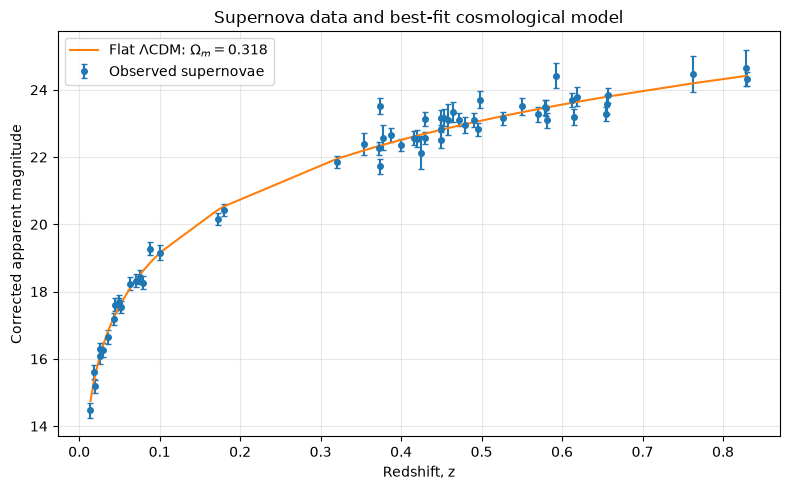

In [41]:

Omega_m_fit=MLE[0]
intercept_fit=MLE[1]

m_fit = np.array([predicted_magnitude(zi, Omega_m_fit, intercept_fit) for zi in z])

# Sort the data by redshift for a clean model curve
order = np.argsort(z)

plt.figure(figsize=(8, 5))

plt.errorbar(
    z, m_obs,
    yerr=sigma,
    fmt="o",
    markersize=4,
    capsize=2,
    label="Observed supernovae"
)

plt.plot(z[order],m_fit[order],label=fr"Flat $\Lambda$CDM: $\Omega_m={Omega_m_fit:.3f}$")

plt.xlabel("Redshift, z")
plt.ylabel("Corrected apparent magnitude")
plt.title("Supernova data and best-fit cosmological model")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

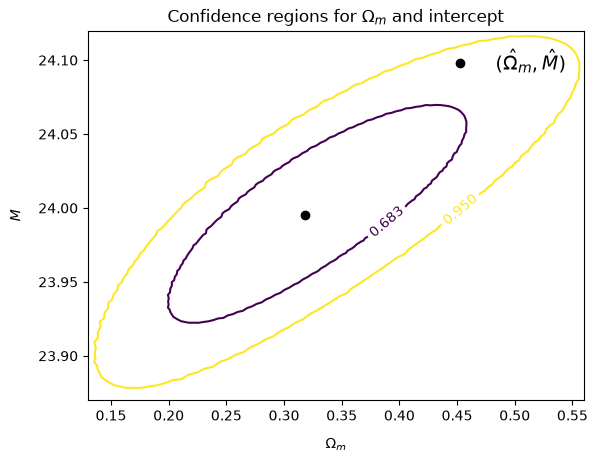

In [42]:
# Confidence region from lnL = lnLmax - Q/2 (here for theta and xi)
# where Q is the chi2 quantile of CL = 1-alpha = 0.683 and 0.95 for 2 dof.
if not(m.fixed['Omega_m'] | m.fixed['intercept']):
    fig, ax = plt.subplots(1,1)
    m.draw_mncontour('Omega_m', 'intercept', cl=[0.683, 0.95], size=200);
    plt.plot(MLE[0], MLE[1], marker='o', linestyle='None', color='black', label=r'$(\hat{\Omega}_m, \hat{M})$')
    plt.xlabel(r'$\Omega_m$', labelpad=10)
    plt.ylabel(r'$M$', labelpad=10)
    plt.xlim(0.13,0.56)
    plt.ylim(23.87, 24.12)
    #plt.subplots_adjust(left=0.2, right=0.9, top=0.9, bottom=0.2)
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles, labels, loc='upper right', fontsize=14, frameon=False)
    #plt.figtext(0.3, 0.93, r'$\ln L = \ln L_{\rm max} - \frac{1}{2} F^{-1}_{\chi^2}(1-\alpha;N)$')
    #plt.figtext(0.3, 0.93, 'Confidence regions for $\Omega_m$ and intercept')
    plt.title("Confidence regions for $\Omega_m$ and intercept")

    plt.show()

Profiling and the fitted plot are promising also the value of density parameter of matter is again near 0.3 which is good. One of the key takeaways from the Confidence contours is that it is tilted on the right which indicates a positive correlation between M and $\Omega_m$. This implies that there's a so called cosmological degeneracy between M and $\Omega_m$ i.e. if we change them in same manner our observables remain unchanged.

Here's a quick summary of what we did above:

* We took a Supernova dataset and Identified different observables with their errors.
* We reformatted the dataset using pandas and plotted it.
* Then we went on to add different cosological corrections on it and identified the parameters of our data namely the interceot and Density parameter of matter.
* We calculated Negative Log Likelihood and minimized it using two different ways.
* We plotted our best fit model, calculated the goodness of fit, descriptive statistics, Profile Likelihood as well as Confidence intervals of each parameters.
* Our results lined up with the actual observational values and we also found out a positive correlation between the two parameters.



Next we are going to compare two diffrent cosmological models using hypothesis testing. For historical purposes we are going to compare $\Lambda$ CDM model with matter only universe.

###  Define the hypotheses:

$$
\begin{aligned}
H_0 : \Omega_m = 1 &\quad \text{(flat matter-only universe)}, \\
H_1 : 0 < \Omega_m < 1 &\quad \text{(flat $\Lambda$CDM with positive cosmological constant)}
\end{aligned}
$$

Under $H_0$, the expansion function becomes

$$E(z) = \sqrt{(1 + z)^3} = (1 + z)^{3/2}.$$

The luminosity distance is therefore

$$D_L(z) = (1 + z) \int_0^z \frac{dz'}{(1 + z')^{3/2}},$$

which evaluates to

$$\boxed{D_L(z) = 2(1 + z) \left[ 1 - \frac{1}{\sqrt{1 + z}} \right].}$$

This gives us a specific prediction for the supernova magnitudes under the null hypothesis.

Since our original model can give us matter only universe we just use our previous definitions.

In [53]:
parin_null=np.array([1.0, 24.]) # initial parameter values
parname_null=["Omega_m", "intercept"]
parnamelatex_null=[r'$\Omega_m$', r'$intercept$']

parstep = np.array([0.001, .1]) # initial setp sizes
parfix = [True, False] # change these to fix/free parameters
parlim = [(0.,1.), (None, None)] # set limits
m_null = Minuit(neg_log_likelihood, parin_null, name=parname_null)
m_null.errors = parstep
m_null.fixed = parfix
m_null.limits = parlim
m_null.errordef = 0.5 # errors from lnL = lnLmax - 0.5

In [54]:
m_null.migrad()                                        
MLE = m_null.values                                    
sigmaMLE = m_null.errors                               
cov = m_null.covariance                                
rho = m_null.covariance.correlation()                  
    
print(r"par index, name, estimate, standard deviation:")
for i in range(m_null.npar):
    if not m_null.fixed[i]:
        print("{:4d}".format(i), "{:<10s}".format(m_null.parameters[i]), " = ",
         "{:.6f}".format(MLE[i]), " +/- ", "{:.6f}".format(sigmaMLE[i]))

print()
print(r"free par indices, covariance, correlation coeff.:")
for i in range(m_null.npar):
    if not(m_null.fixed[i]):
        for j in range(m_null.npar):
            if not(m_null.fixed[j]):
                print(i, j, "{:.6f}".format(cov[i,j]), "{:.6f}".format(rho[i,j]))



par index, name, estimate, standard deviation:
   1 intercept   =  24.242155  +/-  0.028332

free par indices, covariance, correlation coeff.:
1 1 0.000803 1.000000


Now we need to define a test statistic for our heed. We are going to use likelihood ratio defined as:


$$T = -2 \ln \left( \frac{L(H_0)}{L(H_1)} \right) .$$

Since  negative log-likelihood is $\chi^2 / 2$, this simplifies to

$$\boxed{T = \chi^2_{\text{null}} - \chi^2_{\text{alternative}}} .$$

The logic is straightforward:

* Fit the data with $\Omega_m = 1$ and optimize the intercept. Record $\chi^2_{\text{null}}$.
* Fit the data with $\Omega_m$ free and optimize the intercept. Record $\chi^2_{\text{alternative}}$.
* Calculate $T$. A larger positive value means the free-$\Omega_m$ model fits substantially better.

The null model is nested within the alternative model, because setting $\Omega_m = 1$ in the flat $\Lambda\text{CDM}$ model eliminates the cosmological constant.

One subtlety matters here: $\Omega_m = 1$ is a boundary value of the allowed parameter space, not an interior value. For the one-sided test $\Omega_m < 1$ against $\Omega_m = 1$, the usual large-sample likelihood-ratio reference distribution is a 50:50 mixture of a point mass at zero and a $\chi^2$ distribution with one degree of freedom. We'll account for that when calculating the p-value.
```[cite: 1]


In [55]:
# Minimum chi-square for each hypothesis
chi2_null = 2 * m_null.fval
chi2_alt = 2 * m.fval

# Likelihood-ratio test statistic
T = chi2_null - chi2_alt

print("Null hypothesis:")
print("Omega_m =", m_null.values["Omega_m"])
print("Chi-square =", chi2_null)

print("\nAlternative hypothesis:")
print("Omega_m =", m.values["Omega_m"])
print("Chi-square =", chi2_alt)

print("\nTest statistic T =", T)

Null hypothesis:
Omega_m = 1.0
Chi-square = 136.7717121016242

Alternative hypothesis:
Omega_m = 0.3182680546778535
Chi-square = 103.13631561209885

Test statistic T = 33.635396489525334


The test statistic is much larger than 1 indicating our alternate hypothesis i.e. $\Lambda$ CDM cosmology is a much better fit to our data. Now one issue as mentioned before the Null hypothesis lies on a boundary of the parameter space. This matters because in usual parameter estimation we expect our Hyptheses to lie within the boundaries. Now say the alternate Hypothesis is on the boundary, then the parameter could fluctuate on either side of it causing it to go in null region. Since it has a 50-50 change of going up or down the boundary we have to account for an extra $\frac{1}{2}$ term in our chi square minimization/distribution.

We calculate the p value using the modified formula for one sided test:

For a positive observed statistic $T_{\text{obs}}$:

$$P(T \ge T_{\text{obs}}) \approx \frac{1}{2} P(\chi^2_1 \ge T_{\text{obs}}).$$

Hence,

$$\boxed{p \approx \frac{1}{2} \text{SF}_{\chi^2_1}(T_{\text{obs}})}.$$


where SF is the survival function describing the inverse CDF.

In [56]:
from scipy.stats import chi2

p_value = 0.5 * chi2.sf(T, df=1)

print("Test statistic =", T)
print("p-value =", p_value)

Test statistic = 33.635396489525334
p-value = 3.32360236421077e-09


Significance levels determine the probability of rejecting the null hypothesis and usually we are the ones who decide how much significance should be allowed. We see the p-value is of 10^-9 order. So it is safe to say with in the 95% significance we can reject the null hypothesis.

Next we could try to visullay see how two models compare with the actual data by plotting the best fits in the same plots.

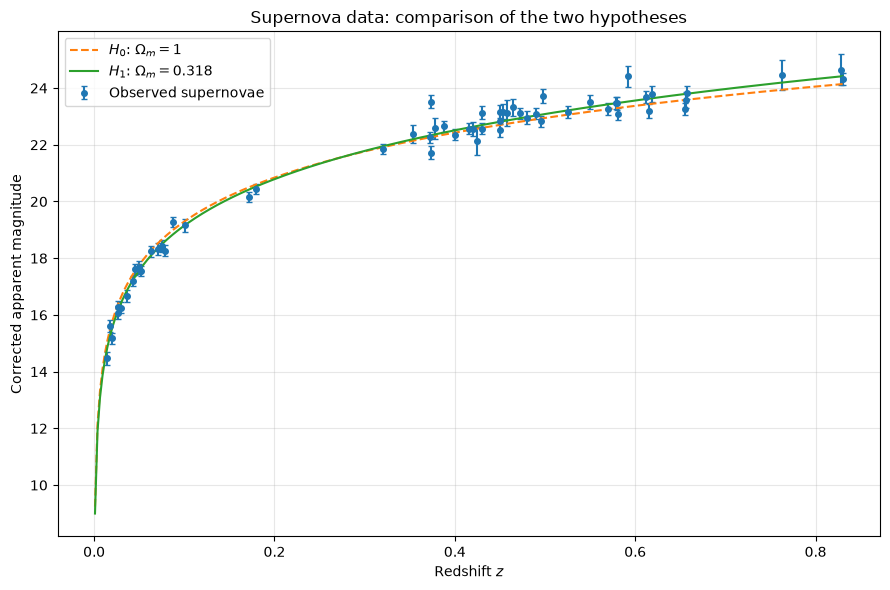

In [58]:
# Best-fit parameters from the two hypothesis tests
Omega_m_null = m_null.values["Omega_m"]
intercept_null = m_null.values["intercept"]

Omega_m_alt = m.values["Omega_m"]
intercept_alt = m.values["intercept"]

# Smooth redshift grid for drawing the theoretical curves
# This is necessary otherwise the curves will be drawn only at the observed redshifts, which may not look smooth.!!!!
z_plot = np.linspace(0.001, z.max(), 300)

# Predicted apparent magnitudes
m_null_plot = np.array([predicted_magnitude(zi, Omega_m_null, intercept_null) for zi in z_plot])

m_alt_plot = np.array([predicted_magnitude(zi, Omega_m_alt, intercept_alt) for zi in z_plot])

# Plot the observed supernova data
plt.figure(figsize=(9, 6))

plt.errorbar(
    z, m_obs,
    yerr=sigma,
    fmt="o",
    markersize=4,
    capsize=2,
    label="Observed supernovae"
)

# Plot the null-hypothesis prediction
plt.plot(z_plot, m_null_plot,linestyle="--",label=rf"$H_0$: $\Omega_m=1$")

# Plot the alternative-hypothesis prediction
plt.plot(z_plot, m_alt_plot,linestyle="-",label=rf"$H_1$: $\Omega_m={Omega_m_alt:.3f}$")

plt.xlabel("Redshift $z$")
plt.ylabel("Corrected apparent magnitude")
plt.title("Supernova data: comparison of the two hypotheses")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

We conclude by summarizing our hypothesis testing exercise:

* We defined two hypotheses one corresponding to a matter only universe and othe our $\Lambda$ CDM one.
* We constructed a test statistic namely the likelihood ratio to compare these two.
* We found out the p-value i.e. how the Null hypothesis holds under extreme conditions.
* We also verified by defining significance levels that our Alternate hypothesis is better.